<a href="https://colab.research.google.com/github/SenudaR20/visual-anomaly-detection/blob/main/algorithms/CAE/CAE_Bottle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import Libraries

In [1]:
import os
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image

from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, Model
from sklearn.metrics import confusion_matrix, classification_report

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


In [2]:
# connecting google Drive

from google .colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
DATA_ROOT = Path(
    "/content/drive/MyDrive/MvTech_Dataset/bottle"
)

TRAIN_DIR = DATA_ROOT / "train" / "good"
TEST_DIR = DATA_ROOT / "test"
MASK_DIR = DATA_ROOT / "ground_truth"

# Check data inside the folders

print("Dataset path:", DATA_ROOT)
print("Training folder exists:", TRAIN_DIR.exists())
print("Test folder exists:", TEST_DIR.exists())
print("Ground-truth folder exists:", MASK_DIR.exists())

if not TRAIN_DIR.exists():
  raise FileNotFoundError("Training folder not found")
if not TEST_DIR.exists():
  raise FileNotFoundError("Test folder not found")
if not MASK_DIR.exists():
  raise FileNotFoundError("Ground-truth folder not found")

Dataset path: /content/drive/MyDrive/MvTech_Dataset/bottle
Training folder exists: True
Test folder exists: True
Ground-truth folder exists: True


In [4]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}
def get_images(folder):
    folder = Path(folder)

    if not folder.exists():
        return []

    return sorted([
        path for path in folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ])

# Normal images used to train the CAE
train_images = get_images(TRAIN_DIR)

# Images used for evaluation
test_images = []

for folder in sorted(TEST_DIR.iterdir()):
    if folder.is_dir():
        for image_path in get_images(folder):
            test_images.append(image_path)

print("Normal training images:", len(train_images))
print("Total test images:", len(test_images))

print("\nFirst five training image paths:")
for path in train_images[:5]:
    print(path)


Normal training images: 209
Total test images: 83

First five training image paths:
/content/drive/MyDrive/MvTech_Dataset/bottle/train/good/000.png
/content/drive/MyDrive/MvTech_Dataset/bottle/train/good/001.png
/content/drive/MyDrive/MvTech_Dataset/bottle/train/good/002.png
/content/drive/MyDrive/MvTech_Dataset/bottle/train/good/003.png
/content/drive/MyDrive/MvTech_Dataset/bottle/train/good/004.png


Check the test categories

In [5]:
for folder in sorted(TEST_DIR.iterdir()):
    if folder.is_dir():
        images = get_images(folder)
        print(f"{folder.name}: {len(images)} images")

broken_large: 20 images
broken_small: 22 images
contamination: 21 images
good: 20 images


Visualize the images

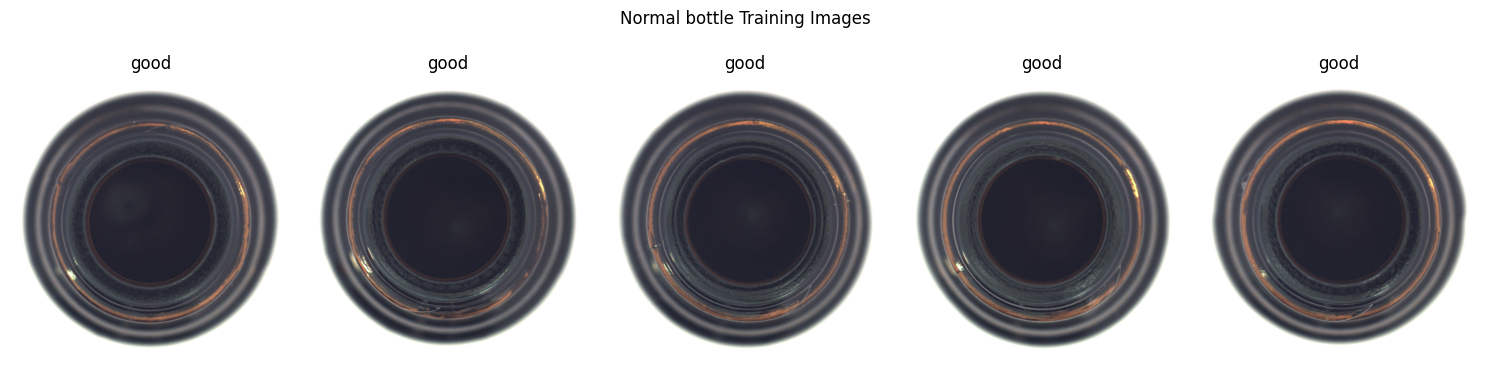

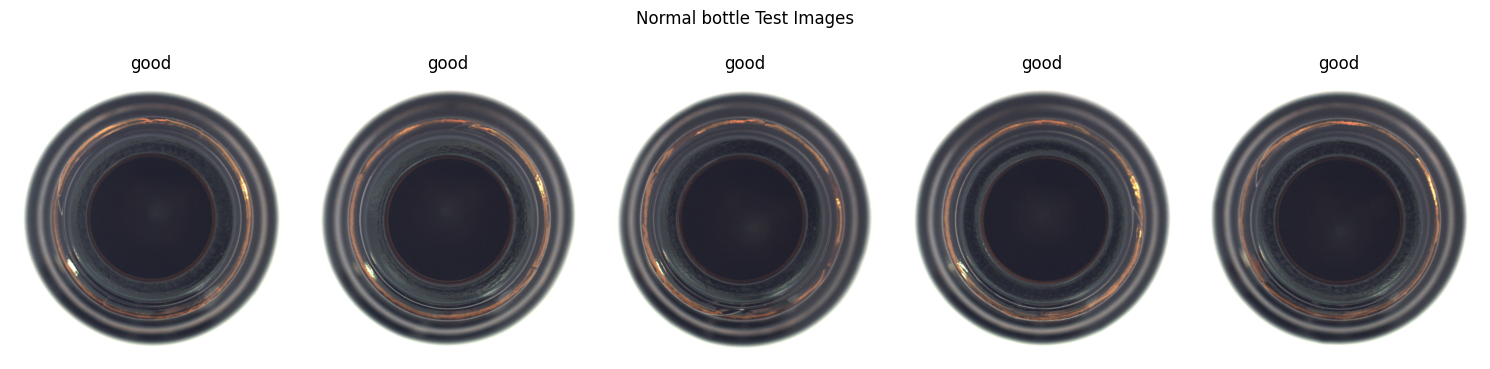

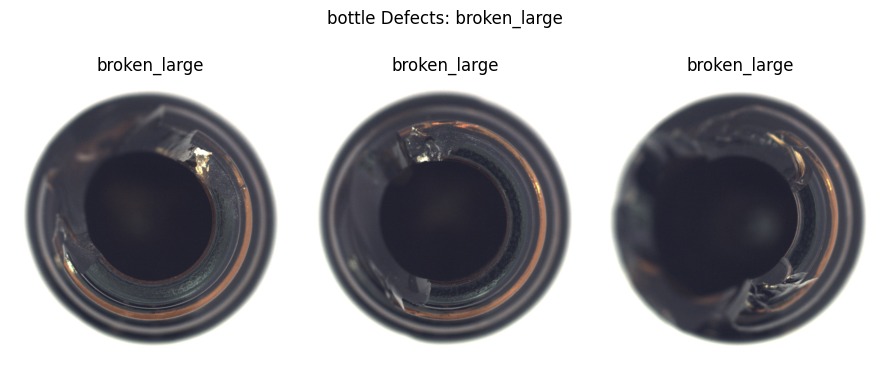

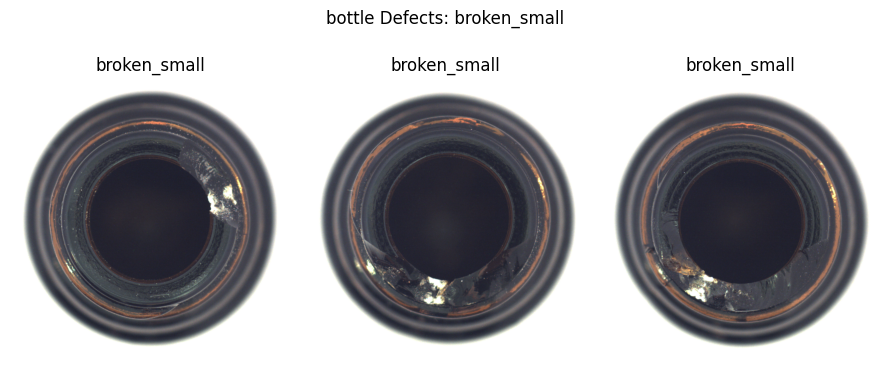

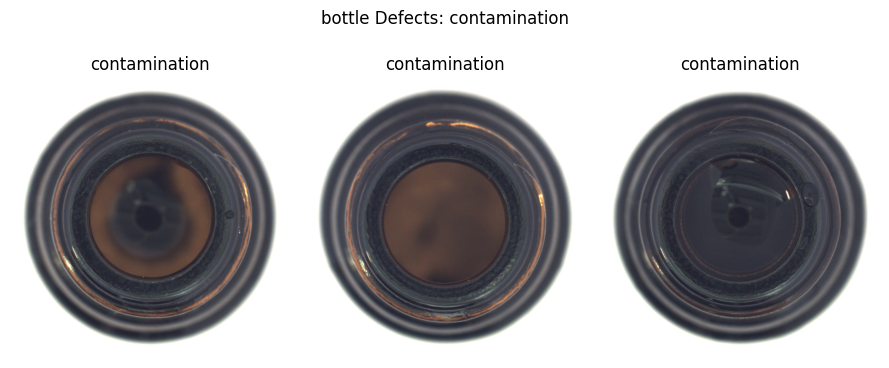

In [11]:
def display_images(image_paths, title, n=5):
    if len(image_paths) == 0:
        print(f"No images found: {title}")
        return

    selected = random.sample(
        list(image_paths),
        min(n, len(image_paths))
    )

    fig, axes = plt.subplots(
        1, len(selected),
        figsize=(3 * len(selected), 4)
    )

    if len(selected) == 1:
        axes = [axes]

    for ax, path in zip(axes, selected):
        image = Image.open(path).convert("RGB")
        ax.imshow(image)
        ax.set_title(Path(path).parent.name)
        ax.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


# Normal training images
display_images(
    train_images,
    "Normal bottle Training Images"
)

# Normal test images
normal_test_images = get_images(TEST_DIR / "good")

display_images(
    normal_test_images,
    "Normal bottle Test Images"
)

# Defective test images
for folder in sorted(TEST_DIR.iterdir()):
    if folder.is_dir() and folder.name != "good":
        display_images(
            get_images(folder),
            f"bottle Defects: {folder.name}",
            n=3
        )

Dataset Summary

In [12]:
print("Normal training images:", len(train_images))
print("Normal test images:", len(normal_test_images))

print("\nTest images by category:")

for folder in sorted(TEST_DIR.iterdir()):
    if folder.is_dir():
        print(f"{folder.name}: {len(get_images(folder))} images")


Normal training images: 209
Normal test images: 20

Test images by category:
broken_large: 20 images
broken_small: 22 images
contamination: 21 images
good: 20 images


Preprocess the normal training images

In [13]:
IMG_HEIGHT = 128
IMG_WIDTH = 128
CHANNELS = 3

def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")

    image = image.resize(
        (IMG_WIDTH, IMG_HEIGHT),
        Image.Resampling.BILINEAR
    )

    return np.asarray(image, dtype=np.float32) / 255.0


# Load normal training images only
X_train = np.stack([
    preprocess_image(path)
    for path in train_images
])

print("Training array shape:", X_train.shape)
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())


Training array shape: (209, 128, 128, 3)
Minimum pixel value: 0.11764706
Maximum pixel value: 1.0


Split the training data


In [14]:
X_train_final, X_val = train_test_split(X_train,test_size=0.15,random_state=SEED,shuffle=True)

print("Training set shape:", X_train_final.shape)
print("Validation set shape:", X_val.shape)

Training set shape: (177, 128, 128, 3)
Validation set shape: (32, 128, 128, 3)


Build the Convolutional Autoencoder

In [15]:
IMG_SHAPE = (IMG_HEIGHT,IMG_WIDTH,CHANNELS)

# Encoder

inputs = layers.Input(shape=IMG_SHAPE) # creating input layer

x = layers.Conv2D(32,kernel_size=3, strides=2,padding="same")(inputs) # First encoder block
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

x = layers.Conv2D(64,kernel_size=3, strides=2,padding="same")(x) # Second encoder block
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

x = layers.Conv2D(128,kernel_size=3, strides=2,padding="same")(x) #Third encoder block
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

x =layers.Conv2D(128,kernel_size=3,strides=2,padding="same")(x) #Fourth encoder block
x = layers.BatchNormalization()(x)
latent = layers.ReLU(name="latent_representation")(x)

# Decoder

x = layers.Conv2DTranspose(128, kernel_size=3, strides=2, padding="same")(latent) # First decoder block
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

x = layers.Conv2DTranspose(64, kernel_size=3, strides=2, padding="same")(x) # Second decoder block
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

x = layers.Conv2DTranspose(32, kernel_size=3, strides=2, padding="same")(x) # Third decoder block
x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

outputs = layers.Conv2DTranspose(3, kernel_size=3, strides=2, padding="same", activation="sigmoid")(x)

# Complete Autoencoder

autoencoder = Model(inputs=inputs, outputs=outputs, name="bottle_CAE")
autoencoder.summary()


Model: "bottle_CAE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_representation (ReLU)    │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 16, 16, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 32, 32, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_10 (ReLU)                 │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_6              │ (None, 64, 64, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 483,843 (1.85 MB)

 Trainable params: 482,691 (1.84 MB)

 Non-trainable params: 1,152 (4.50 KB)

COMPILE THE AUTOENCODER

In [16]:
LEARNING_RATE = 0.001

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="mean_squared_error"
)

print("Autoencoder compiled successfully.")


Autoencoder compiled successfully.


In [17]:
# Check the model output shape without training

sample_batch = X_train_final[:2]
sample_reconstruction = autoencoder(
    sample_batch,
    training=False
)

print("Input shape:", sample_batch.shape)
print("Output shape:", sample_reconstruction.shape)

Input shape: (2, 128, 128, 3)
Output shape: (2, 128, 128, 3)


Training and validation datasets

In [18]:

BATCH_SIZE = 16

# Training dataset: normal images are both inputs and targets
train_ds = tf.data.Dataset.from_tensor_slices((X_train_final, X_train_final))

#shuffle the training dataset
train_ds = (
    train_ds
    .shuffle(len(X_train_final), seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Validation dataset: also contains only normal images
val_ds = tf.data.Dataset.from_tensor_slices((X_val, X_val))

val_ds = (
    val_ds
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Batch size:", BATCH_SIZE)


Training batches: 12
Validation batches: 2
Batch size: 16


Set up model saving and training callbacks

In [19]:
OUTPUT_DIR = Path("/content/drive/MyDrive/CAE_bottle_Results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(OUTPUT_DIR / "best_cae.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(OUTPUT_DIR / "training_log.csv")
    )
]

print("Results folder:", OUTPUT_DIR)
print("Callbacks configured successfully.")

Results folder: /content/drive/MyDrive/CAE_bottle_Results
Callbacks configured successfully.


Training the CAE

In [20]:

EPOCHS = 50

history = autoencoder.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

# Save the final model with the best restored weights
autoencoder.save(str(OUTPUT_DIR / "final_cae.keras"))

print("Training completed.")
print("Model saved to:", OUTPUT_DIR)


Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 545ms/step - loss: 0.1214
Epoch 1: val_loss improved from None to 0.12672, saving model to /content/drive/MyDrive/CAE_bottle_Results/best_cae.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CAE_bottle_Results/best_cae.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 19s 647ms/step - loss: 0.1056 - val_loss: 0.1267
Epoch 2/50
10/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0600
Epoch 2: val_loss improved from 0.12672 to 0.11245, saving model to /content/drive/MyDrive/CAE_bottle_Results/best_cae.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CAE_bottle_Results/best_cae.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0514 - val_loss: 0.1124
Epoch 3/50
 9/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0301
Epoch 3: val_loss improved from 0.11245 to 0.09440, saving model to /content/drive/MyDrive/CAE_bottle_Results/best_cae.keras

Epoch 3: finished saving model to /content/drive/MyDrive/CAE_bottle_Results/best_cae.keras
12/

Plot the training results


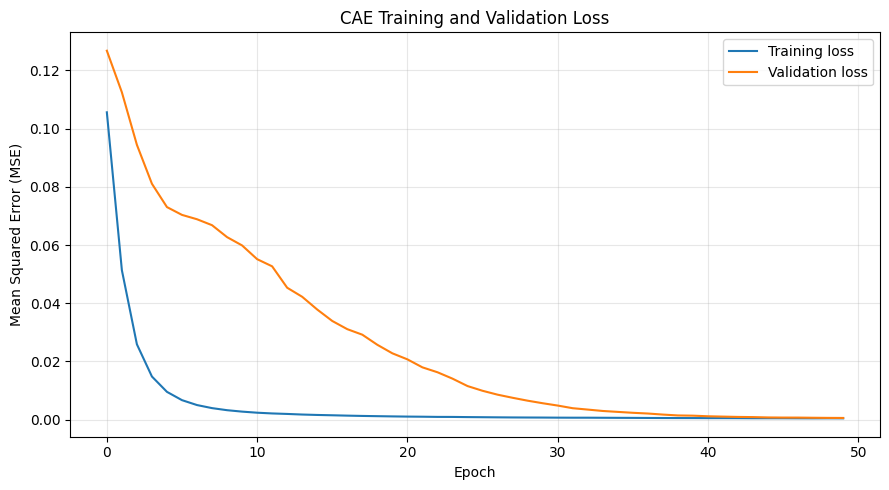

Best epoch: 50
Best validation loss: 0.000611


In [21]:

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("CAE Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

best_epoch = np.argmin(history.history["val_loss"]) + 1
best_val_loss = min(history.history["val_loss"])

print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 6))


Load the best CAE model

In [22]:

BEST_MODEL_PATH = OUTPUT_DIR / "best_cae.keras"

autoencoder = tf.keras.models.load_model(BEST_MODEL_PATH)

print("Best CAE model loaded successfully.")
print("Model input shape:", autoencoder.input_shape)
print("Model output shape:", autoencoder.output_shape)


Best CAE model loaded successfully.
Model input shape: (None, 128, 128, 3)
Model output shape: (None, 128, 128, 3)


Visualize original and reconstructed images

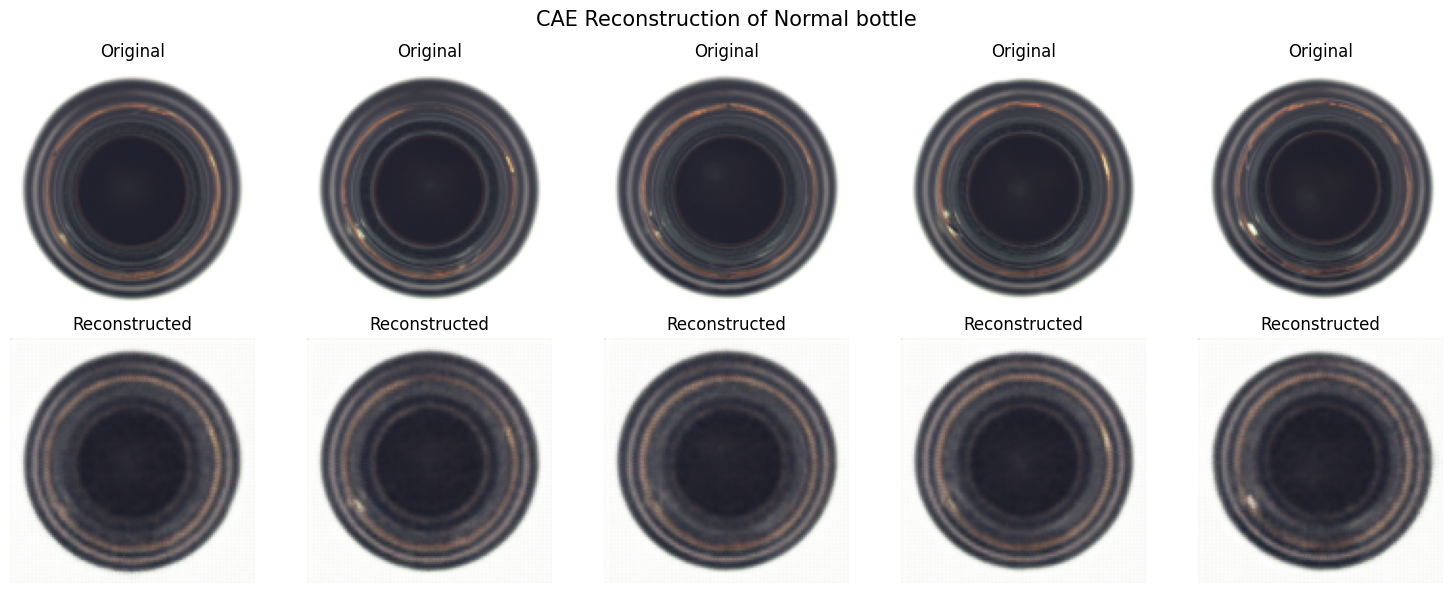

In [23]:

# Select five normal validation images
n = min(5, len(X_val))
sample_images = X_val[:n]

# Reconstruct the images
reconstructed_images = autoencoder.predict(sample_images, verbose=0)

plt.figure(figsize=(15, 6))

for i in range(n):
    # Original image
    plt.subplot(2, n, i + 1)
    plt.imshow(sample_images[i])
    plt.title("Original")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, n, n + i + 1)
    plt.imshow(np.clip(reconstructed_images[i], 0, 1))
    plt.title("Reconstructed")
    plt.axis("off")

plt.suptitle("CAE Reconstruction of Normal bottle", fontsize=15)
plt.tight_layout()
plt.show()


Visualize reconstruction error maps

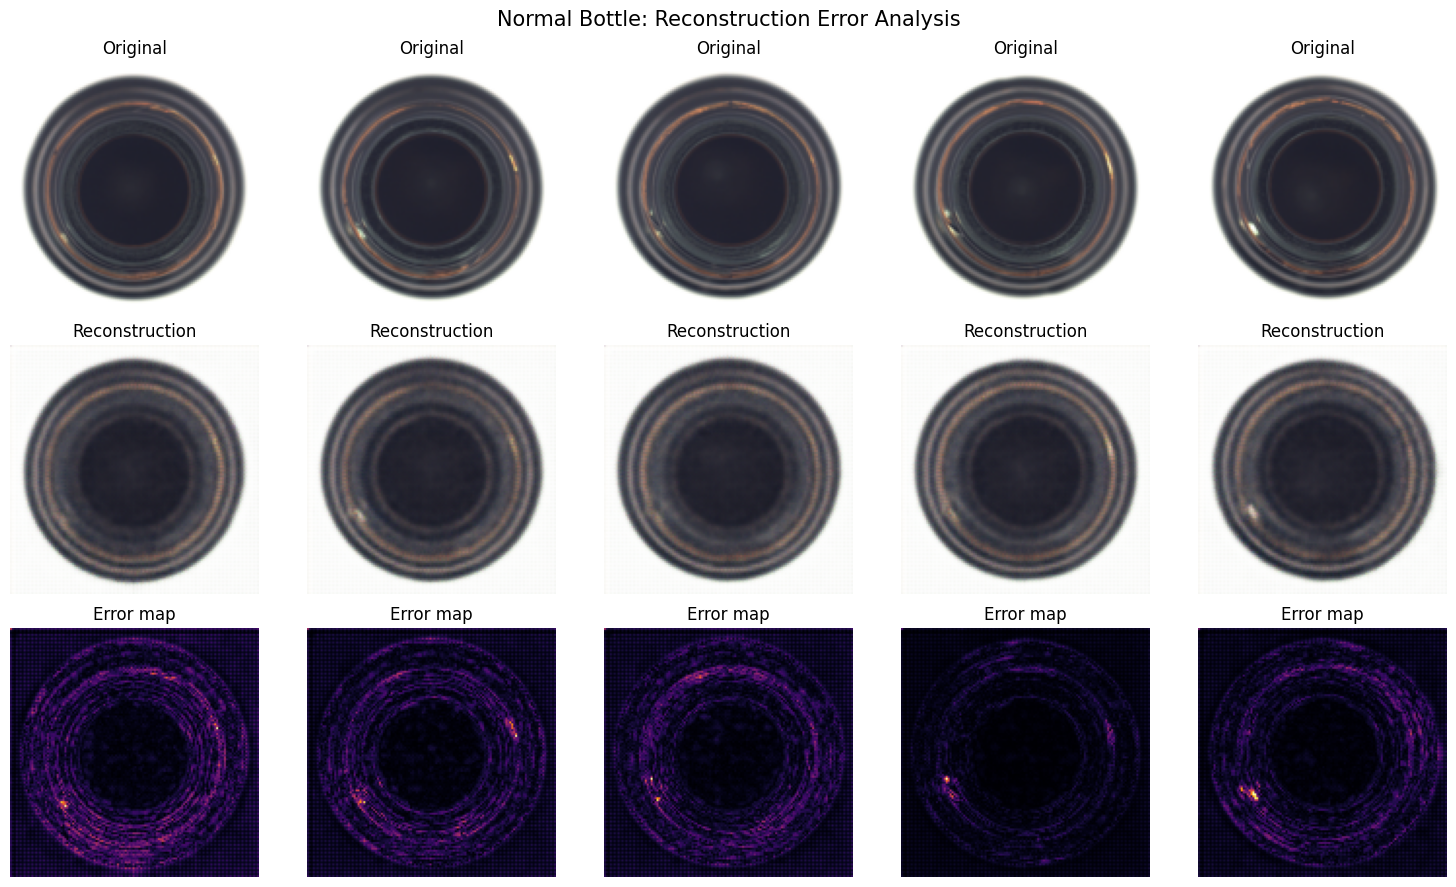

Mean reconstruction error: 0.017923973500728607
Maximum pixel error: 0.41171273589134216


In [24]:

# Mean absolute reconstruction error for each pixel
error_maps = np.mean(
    np.abs(sample_images - reconstructed_images),
    axis=-1
)

plt.figure(figsize=(15, 9))

for i in range(n):
    plt.subplot(3, n, i + 1)
    plt.imshow(sample_images[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(3, n, n + i + 1)
    plt.imshow(reconstructed_images[i])
    plt.title("Reconstruction")
    plt.axis("off")

    plt.subplot(3, n, 2 * n + i + 1)
    plt.imshow(error_maps[i], cmap="inferno")
    plt.title("Error map")
    plt.axis("off")

plt.suptitle("Normal Bottle: Reconstruction Error Analysis", fontsize=15)
plt.tight_layout()
plt.show()

print("Mean reconstruction error:", float(np.mean(error_maps)))
print("Maximum pixel error:", float(np.max(error_maps)))


Load and label the test images

In [25]:

# Identify normal and defective test images
test_labels = np.array([
    0 if image_path.parent.name == "good" else 1
    for image_path in test_images
])

test_categories = np.array([
    image_path.parent.name
    for image_path in test_images
])

# Load all test images using the same preprocessing as training
X_test = np.stack([
    preprocess_image(image_path)
    for image_path in test_images
])

print("Test image array:", X_test.shape)
print("Total test images:", len(test_images))
print("Normal test images:", int(np.sum(test_labels == 0)))
print("Defective test images:", int(np.sum(test_labels == 1)))
print("\nImages by category:")

for category in sorted(set(test_categories)):
    print(f"{category}: {int(np.sum(test_categories == category))}")


Test image array: (83, 128, 128, 3)
Total test images: 83
Normal test images: 20
Defective test images: 63

Images by category:
broken_large: 20
broken_small: 22
contamination: 21
good: 20


Calculate anomaly scores

In [26]:

# Reconstruct test images in batches
X_reconstructed = autoencoder.predict(
    X_test,
    batch_size=16,
    verbose=1
)

# Pixel-level anomaly maps: shape (N, 128, 128)
test_error_maps = np.mean(
    np.abs(X_test - X_reconstructed),
    axis=-1
)

# Image-level anomaly score: average error across all pixels
image_anomaly_scores = np.mean(
    test_error_maps,
    axis=(1, 2)
)

print("Anomaly maps shape:", test_error_maps.shape)
print("Image scores shape:", image_anomaly_scores.shape)
print("Mean normal score:", round(float(
    image_anomaly_scores[test_labels == 0].mean()
), 6))
print("Mean defective score:", round(float(
    image_anomaly_scores[test_labels == 1].mean()
), 6))


6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 198ms/step
Anomaly maps shape: (83, 128, 128)
Image scores shape: (83,)
Mean normal score: 0.018475
Mean defective score: 0.0207


Evaluate image-level detection

Image-level ROC-AUC: 0.8587


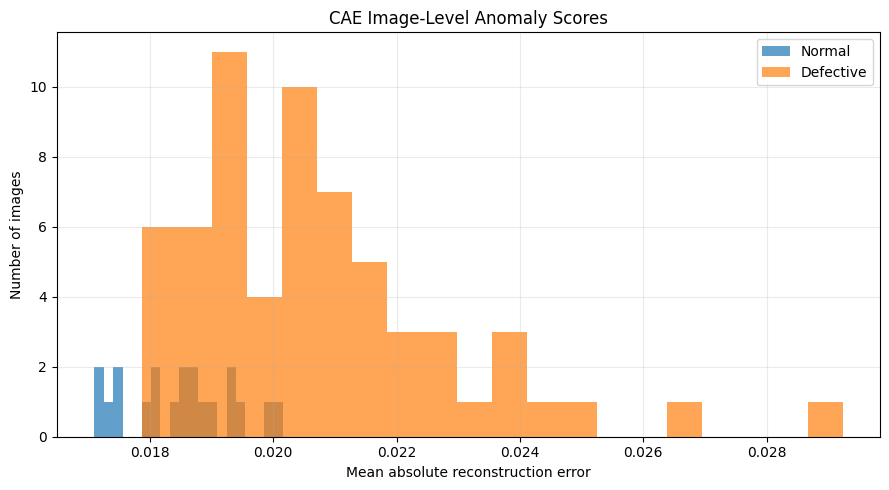

In [28]:

from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
    classification_report
)

if len(np.unique(test_labels)) == 2:
    image_roc_auc = roc_auc_score(
        test_labels,
        image_anomaly_scores
    )
    print(f"Image-level ROC-AUC: {image_roc_auc:.4f}")
else:
    print("ROC-AUC cannot be calculated: the test set needs both classes.")

plt.figure(figsize=(9, 5))

plt.hist(
    image_anomaly_scores[test_labels == 0],
    bins=20,
    alpha=0.7,
    label="Normal"
)

plt.hist(
    image_anomaly_scores[test_labels == 1],
    bins=20,
    alpha=0.7,
    label="Defective"
)

plt.xlabel("Mean absolute reconstruction error")
plt.ylabel("Number of images")
plt.title("CAE Image-Level Anomaly Scores")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


Select a threshold using normal validation images


In [29]:



# Reconstruct normal validation images
val_reconstructions = autoencoder.predict(X_val,batch_size=16,verbose=1)

# Calculate one anomaly score per validation image
val_error_maps = np.mean(np.abs(X_val - val_reconstructions),axis=-1)

val_anomaly_scores = np.mean(val_error_maps,axis=(1, 2))

# Set threshold at the 95th percentile of normal validation scores
THRESHOLD_PERCENTILE = 95

anomaly_threshold = np.percentile(val_anomaly_scores,THRESHOLD_PERCENTILE)

print(f"Threshold percentile: {THRESHOLD_PERCENTILE}")
print(f"Selected anomaly threshold: {anomaly_threshold:.6f}")
print("Validation images classified as anomalous:",
      int(np.sum(val_anomaly_scores > anomaly_threshold)),
      "out of", len(val_anomaly_scores))


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Threshold percentile: 95
Selected anomaly threshold: 0.019482
Validation images classified as anomalous: 2 out of 32


Apply the threshold to the test set

In [30]:

# 0 = normal, 1 = anomalous
test_predictions = (
    image_anomaly_scores > anomaly_threshold
).astype(int)

print("Confusion matrix:")
print(confusion_matrix(test_labels, test_predictions))

print("\nClassification report:")
print(classification_report(
    test_labels,
    test_predictions,
    target_names=["Normal", "Defective"],
    zero_division=0
))


Confusion matrix:
[[17  3]
 [20 43]]

Classification report:
              precision    recall  f1-score   support

      Normal       0.46      0.85      0.60        20
   Defective       0.93      0.68      0.79        63

    accuracy                           0.72        83
   macro avg       0.70      0.77      0.69        83
weighted avg       0.82      0.72      0.74        83



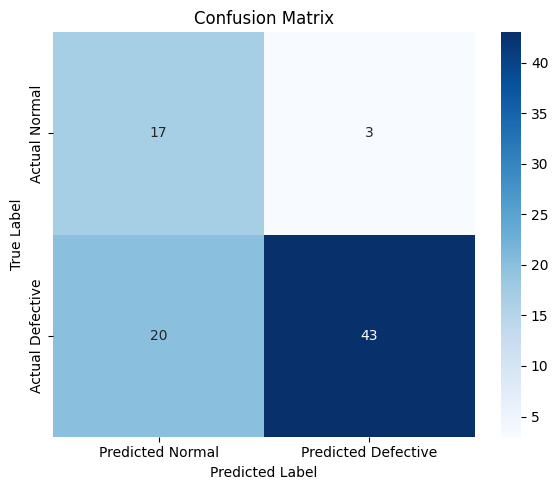

In [31]:
import seaborn as sns
# Compute confusion matrix
cm = confusion_matrix(test_labels, test_predictions)

# Plot
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Normal", "Predicted Defective"],
    yticklabels=["Actual Normal", "Actual Defective"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()